In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [ ]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
df = pd.read_csv(url)

# Drop index column if present in the raw csv
if 'Unnamed: 0' in df.columns:
  df = df.drop(columns=['Unnamed: 0'])

print("First 5 rows:")
df.head()

First 5 rows:


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
print("Shape of dataset (rows, columns):", df.shape)
print("\nData Info:")
df.info()
print("\nStatistical Summary:")
display(df.describe())
print("\nMissing Values Count:")
print(df.isnull().sum())

Shape of dataset (rows, columns): (200, 4)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Statistical Summary:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000



Missing Values Count:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64


In [ ]:
# 1. Clean up column names (removes hidden spaces and makes them lowercase)
df.columns = df.columns.str.strip().str.lower()

# 2. Select features and target using clean lowercase names
X = df[['tv', 'radio', 'newspaper']]
y = df['sales']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (200, 3)
Target (y) shape: (200,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training instances: {X_train.shape[0]}")
print(f"Testing instances:  {X_test.shape[0]}")

Training instances: 160
Testing instances:  40


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (b0):", model.intercept_)
print("Coefficients (b1, b2, b3):", model.coef_)

Intercept (b0): 2.979067338122629
Coefficients (b1, b2, b3): [0.04472952 0.18919505 0.00276111]


In [ ]:
y_pred = model.predict(X_test)

comparison_df = pd.DataFrame(
    {'Actual Sales': y_test.values, 'Predicted Sales': np.round(y_pred, 2)}
)
comparison_df.head(10)

,Actual Sales,Predicted Sales
0,16.9,16.41
1,22.4,20.89
2,21.4,21.55
3,7.3,10.61
4,24.7,22.11
5,12.6,13.11
6,22.3,21.06
7,8.4,7.46
8,11.5,13.61
9,14.9,15.16


In [ ]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance Metrics ---")
print(f"Mean Squared Error (MSE)      : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R²)          : {r2:.4f}")

--- Model Performance Metrics ---
Mean Squared Error (MSE)      : 3.1741
Root Mean Squared Error (RMSE): 1.7816
R-squared Score (R²)          : 0.8994


In [ ]:
new_ad_spend = pd.DataFrame({'tv': [100], 'radio': [30], 'newspaper': [20]})

predicted_sales = model.predict(new_ad_spend)
print(f"Predicted Sales: {predicted_sales[0]:.2f}")

Predicted Sales: 13.18


Final Regression Equation[cite: 2]:
Sales = 2.9791 + (0.0447 * TV) + (0.1892 * Radio) + (0.0028 * Newspaper)[cite: 2]


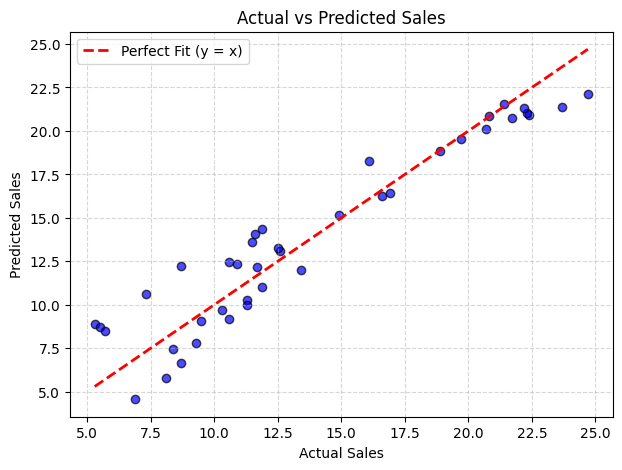

In [ ]:
import matplotlib.pyplot as plt

# 1. Print the final mathematical formula
print(f"Final Regression Equation[cite: 2]:")
print(
    f"Sales = {model.intercept_:.4f} + ({model.coef_[0]:.4f} * TV) + "
    f"({model.coef_[1]:.4f} * Radio) + ({model.coef_[2]:.4f} * Newspaper)[cite: 2]"
)

# 2. Visualize Actual vs. Predicted values
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='blue', edgecolor='k', alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Perfect Fit (y = x)',
)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()